# Function definitions for loading the model

In [1]:
from index_script import detect_jpeg_compression
import os
import pandas as pd
import joblib

loaded_model = joblib.load('models/best_model_svm_(rbf).pkl')
loaded_scaler = joblib.load('models/scaler.pkl')
loaded_feature_columns = joblib.load('models/feature_columns.pkl')

print("Model loaded successfully!")
print(f"Model type: {type(loaded_model).__name__}")
print(f"Number of features: {len(loaded_feature_columns)}")


def check_image(indicators, verbose=True):
    """
    Classifies an image as JFIF or PPM based on calculated indicators.

    Args:
        indicators (dict): Dictionary with calculated image indicators
        verbose (bool): Whether to display detailed information (default: True)

    Returns:
        dict: Dictionary with prediction results
    """
    if indicators is None:
        if verbose:
            print("Error: No indicators!")
        return None

    if verbose:
        print("\n           JFIF vs PPM classification")
        print("-" * 50)

    try:
        # Przygotuj dane do predykcji
        feature_dict = {col: indicators.get(col, 0) for col in loaded_feature_columns}
        X_single = pd.DataFrame([feature_dict])

        if X_single.isnull().any().any():
            if verbose:
                print("\nMissing data in indicators:")
                print(X_single.isnull().sum()[X_single.isnull().sum() > 0])
            return None

        # Skalowanie i predykcja
        X_single_scaled = loaded_scaler.transform(X_single)
        prediction = loaded_model.predict(X_single_scaled)[0]
        probabilities = loaded_model.predict_proba(X_single_scaled)[0]

        # Results
        if verbose:
            format_name = 'PPM (uncompressed)' if prediction == 1 else 'JFIF (JPEG compression)'
            confidence = max(probabilities) * 100
            print(f"Detected format: {format_name}")
            print(f"Confidence: {confidence:.1f}%")

        return {
            'success': True,
            'prediction': prediction,
            'format': 'PPM' if prediction == 1 else 'JFIF',
            'probabilities': {
                'JFIF': probabilities[0],
                'PPM': probabilities[1]
            },
            'confidence': max(probabilities) * 100
        }

    except Exception as e:
        if verbose:
            print(f"Error: {str(e)}")
            import traceback
            traceback.print_exc()
        return None


print("Function check_image() updated!")

Model loaded successfully!
Model type: SVC
Number of features: 15
Function check_image() updated!


In [2]:
# Wczytanie zapisanego modelu
best_model_path = os.path.join('models', 'best_compression_model.pkl')
loaded_compression_model = joblib.load(best_model_path)

In [3]:
def predict_compression_quality(indicators):
    """
    Predicts JPEG compression quality based on calculated image indicators.

    Args:
        indicators (dict): Dictionary with calculated image indicators

    Returns:
        dict: Dictionary with prediction results containing:
            - predicted_quality: predicted quality (int)
            - indicators: calculated image indicators (dict)
            - success: whether the analysis succeeded (bool)
            - error: error message (str) - only if success=False
    """
    if indicators is None:
        return {
            'success': False,
            'error': "No indicators!",
        }

    print("\n\n           Compression quality prediction")
    print("-" * 50)

    # Wyświetl wskaźniki używane przez model (bez estimated_quality)
    

    try:
        # Przygotuj dane do predykcji
        feature_dict = {col: indicators.get(col, 0) for col in loaded_feature_columns
                        if col != 'estimated_quality'}
        X_single = pd.DataFrame([feature_dict])

        if X_single.isnull().any().any():
            missing = X_single.isnull().sum()[X_single.isnull().sum() > 0]
            return {
                'success': False,
                'error': f"Missing indicator data: {missing.to_dict()}",
            }

        # Predykcja jakości kompresji
        predicted_quality = loaded_compression_model.predict(X_single)[0]

        # Wyświetl wynik
        print(f"Predicted JPEG quality: {predicted_quality:.1f}")

        print("\n\nIndicators used by the model:")
        for key in loaded_feature_columns:
            if key in indicators and key != 'estimated_quality':
                value = indicators[key]
                if isinstance(value, (int, float)):
                    print(f"  {key:30s}: {value:>10.4f}")

        return {
            'success': True,
            'predicted_quality': predicted_quality,
            'indicators': indicators
        }

    except Exception as e:
        import traceback
        error_msg = f"Error: {str(e)}\n{traceback.format_exc()}"
        print(error_msg)
        return {
            'success': False,
            'error': error_msg
        }


print("Function predict_compression_quality() updated!")

Function predict_compression_quality() updated!


# PPM/JFIF prediction and quality estimation

Analiza katalogu: contest-images
Znaleziono 4 plików obrazów



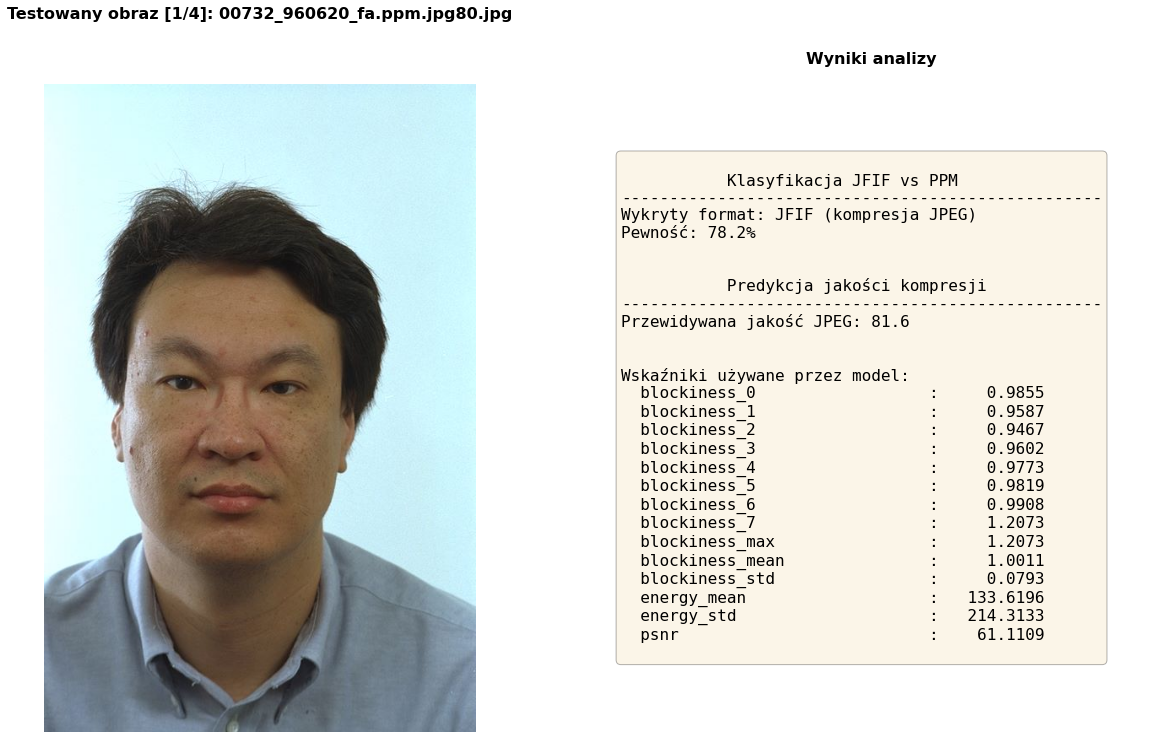

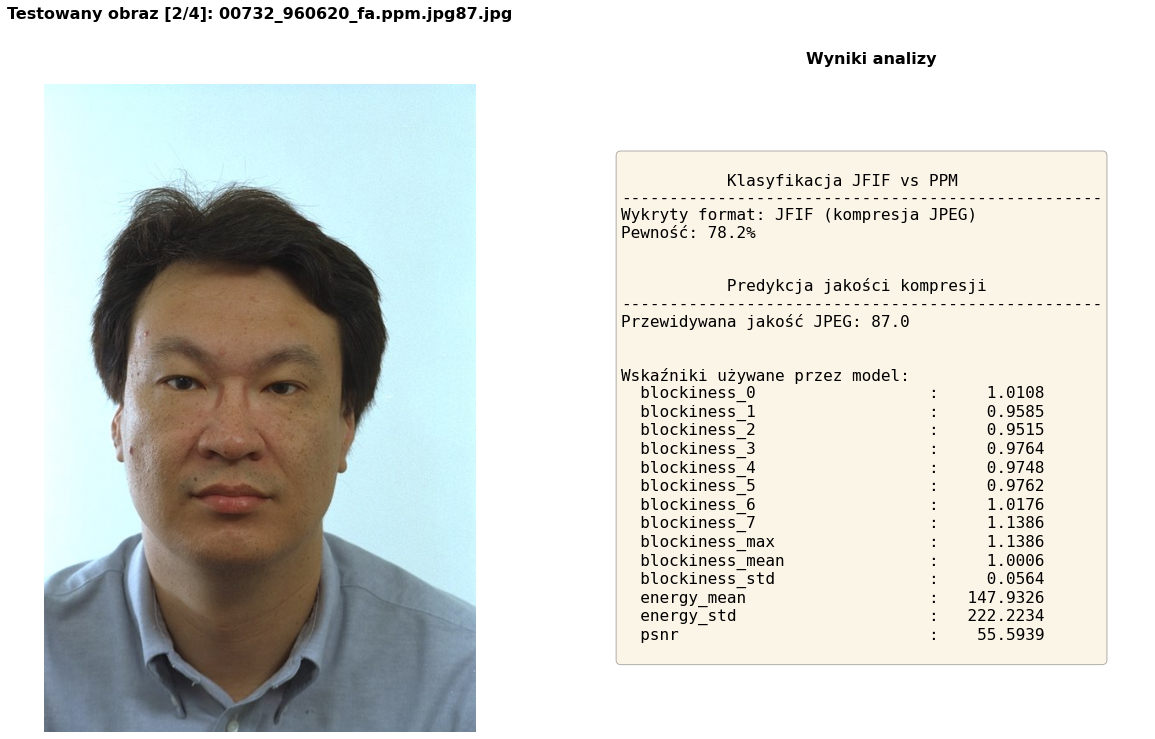

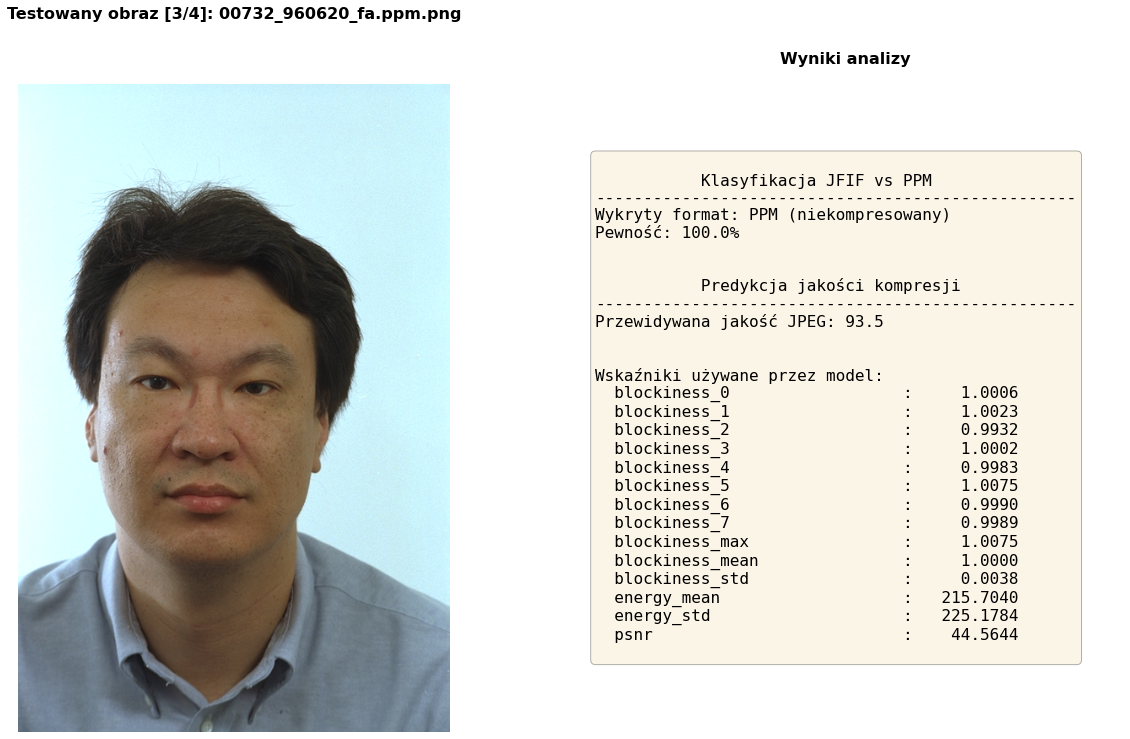

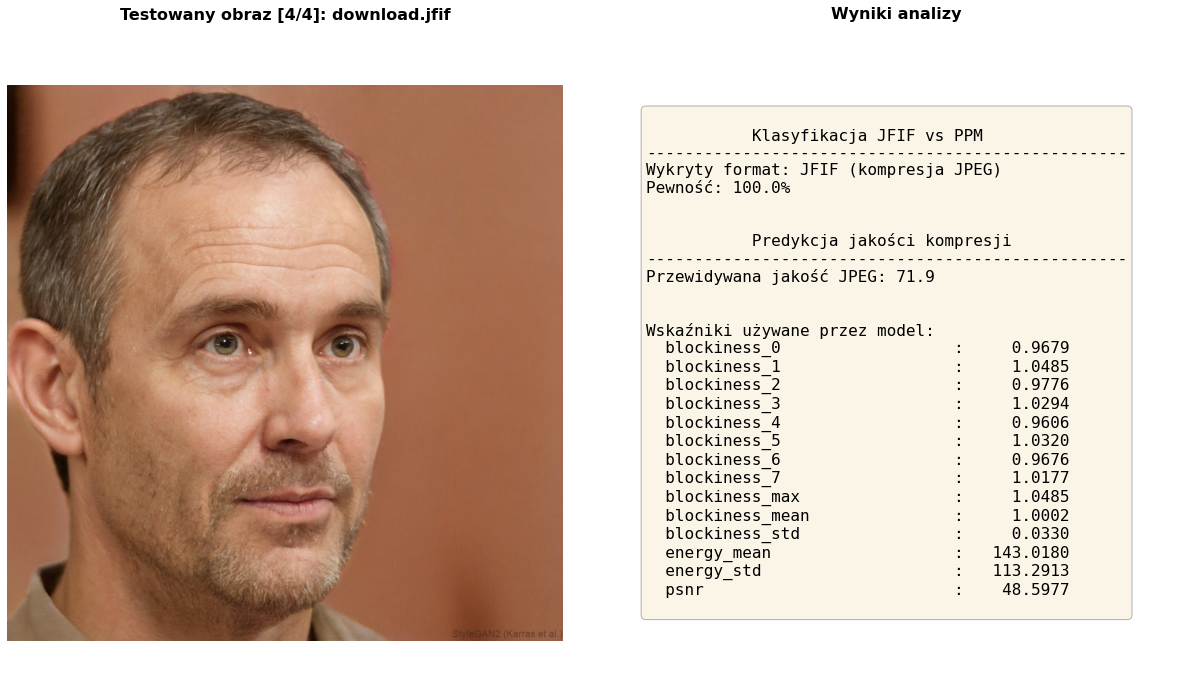

In [ ]:
# ============================
# WSKAŻ KATALOG DO ANALIZY
# ============================
directory_path = 'contest-images'  # Katalog z obrazami do analizy",
# directory_path = 'ColorFeret-unpacked'

# Parametry wyświetlania
TEXT_FONTSIZE = 16  # Rozmiar czcionki tekstu wyników
TITLE_FONTSIZE = 16  # Rozmiar czcionki tytułu

# Rozszerzenia plików obrazów do analizy
IMAGE_EXTENSIONS = ('.jpg', '.jpeg', '.png', '.ppm', '.bmp', '.tiff', '.tif', 'jfif')

print(f"Analyzing directory: {directory_path}")
if os.path.exists(directory_path) and os.path.isdir(directory_path):
    import matplotlib.pyplot as plt
    from PIL import Image
    from io import StringIO
    import sys
    
    # Pobierz listę plików obrazów
    image_files = [f for f in os.listdir(directory_path) 
                   if f.lower().endswith(IMAGE_EXTENSIONS)]
    
    if not image_files:
        print(f"No image file(s) in directory {directory_path}")
    else:
        print(f"Found {len(image_files)} image files\n")
        # print("=" * 70)
        
        # Analizuj każdy plik
        for idx, filename in enumerate(image_files, 1):
            image_path = os.path.join(directory_path, filename)
            # print(f"\n[{idx}/{len(image_files)}] Analiza pliku: {filename}")
            
            try:
                # Oblicz wskaźniki
                indicators = detect_jpeg_compression(image_path)

                if indicators:
                    # Przechwytuj wyniki tekstowe
                    old_stdout = sys.stdout
                    sys.stdout = text_buffer = StringIO()

                    # Klasyfikuj format
                    result_format = check_image(indicators, verbose=True)
                    # Predykcja jakości kompresji
                    quality_result = predict_compression_quality(indicators)

                    # Przywróć stdout i pobierz wyniki
                    sys.stdout = old_stdout
                    text_output = text_buffer.getvalue()

                    # Wyświetl obraz i wyniki obok siebie
                    img = Image.open(image_path)
                    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 10))

                    # Lewy panel - obraz
                    ax1.imshow(img)
                    ax1.axis('off')
                    ax1.set_title(f"Test image [{idx}/{len(image_files)}]: {filename}", 
                                 fontsize=TITLE_FONTSIZE, fontweight='bold', pad=65)

                    # Prawy panel - wyniki tekstowe
                    ax2.axis('off')
                    ax2.text(0.05, 0.5, text_output, transform=ax2.transAxes,
                             fontsize=TEXT_FONTSIZE, verticalalignment='center', fontfamily='monospace',
                             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))
                    ax2.set_title("Analysis results", fontsize=TITLE_FONTSIZE, fontweight='bold', pad=20)

                    plt.subplots_adjust(top=0.95, bottom=0.05, left=0.05, right=0.95, wspace=0.1)
                    plt.show()
                    
                    # print("=" * 70)
                else:
                    print(f"Failed to compute indicators for {filename}")
                    
            except Exception as e:
                print(f"  ✗ Error analyzing {filename}: {str(e)}")
                import traceback
                traceback.print_exc()
            
        # print(f"\n\nAnaliza zakończona. Przeanalizowano {len(image_files)} plików.")
else:
    print(f"Directory '{directory_path}' does not exist!")